# Exploratory data analysis on the training rows

This notebook looks only at the training rows: blocks 1–3 minus the
7-day gap before block 4, i.e. days 0–82. These are exactly the rows the models and every fitted
transform (such as the column pruning) will be trained on.

In [1]:
import sys
from pathlib import Path

# Let the notebook import src/ whether it is opened from notebooks/ or from the project root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data.split import check_no_leak, time_split
from src.utils.config import load_config, set_seed

cfg = load_config()
set_seed(cfg["seed"])
split = cfg["split"]
FIG_DIR = cfg["paths"]["figures_dir"]
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
# Chart colours and a quiet style
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
SURFACE, GRID, AXIS = "#fcfcfb", "#e1e0d9", "#c3c2b7"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.titlecolor": INK, "axes.titlelocation": "left", "axes.titlesize": 11,
    "axes.labelcolor": INK_2, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "lines.linewidth": 2,
})

## 1. Load the training rows

In [3]:
blocked = pd.read_parquet(cfg["paths"]["interim_dir"] / cfg["files"]["blocked"])
train_rows, tune_rows = time_split(blocked, split["train_blocks"], split["tune_blocks"], split["gap_days"])
check_no_leak(blocked.loc[train_rows, "day"], blocked.loc[tune_rows, "day"], split["gap_days"])

df = blocked.loc[train_rows].reset_index(drop=True)
del blocked, train_rows, tune_rows  # nothing from blocks 4-6 is kept

assert set(df["block"].unique()) <= set(split["train_blocks"])
print(f"Training rows: {len(df):,} x {df.shape[1]} columns, "
      f"days {df['day'].min()}-{df['day'].max()}, blocks {sorted(df['block'].unique().tolist())}")

Training rows: 294,193 x 436 columns, days 0-82, blocks [1, 2, 3]


## 2. Class balance

Rows and fraud rate per block. Block 3 is shorter here because its last 7 days (83–89) are the gap.

In [4]:
balance = df.groupby("block").agg(first_day=("day", "min"), last_day=("day", "max"),
                                  rows=("isFraud", "size"), frauds=("isFraud", "sum"))
balance.loc["all"] = [df["day"].min(), df["day"].max(), len(df), df["isFraud"].sum()]
balance["fraud_%"] = (100 * balance["frauds"] / balance["rows"]).round(2)
balance

,first_day,last_day,rows,frauds,fraud_%
block,,,,,
1,0,29,134339,3401,2.53
2,30,59,89399,3577,4.00
3,60,82,70455,2876,4.08
all,0,82,294193,9854,3.35


## 3. Daily volume and fraud rate

Two separate panels, on the count and the rate (vertical lines mark where blocks 2 and 3 start).

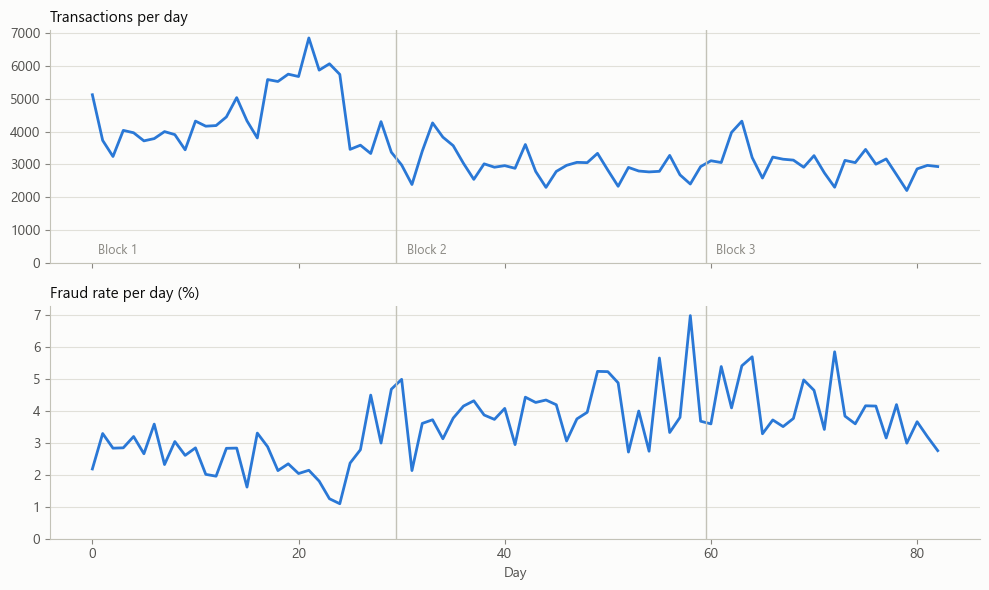

In [5]:
daily = df.groupby("day")["isFraud"].agg(transactions="size", frauds="sum")
daily["fraud_%"] = 100 * daily["frauds"] / daily["transactions"]
block_starts = df.groupby("block")["day"].min()  # first day of each block

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(daily.index, daily["transactions"], color=BLUE)
ax1.set_title("Transactions per day")
ax2.plot(daily.index, daily["fraud_%"], color=BLUE)
ax2.set_title("Fraud rate per day (%)")
ax2.set_xlabel("Day")
for ax in (ax1, ax2):
    ax.set_ylim(bottom=0)
    for start in block_starts.iloc[1:]:
        ax.axvline(start - 0.5, color=AXIS, linewidth=1)
for block, start in block_starts.items():
    ax1.text(start + 0.5, 0.04, f"Block {block}", transform=ax1.get_xaxis_transform(),
             color=MUTED, fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_daily.png", dpi=150)
plt.show()

In [6]:
daily[["transactions", "frauds", "fraud_%"]].describe().round(2)

,transactions,frauds,fraud_%
count,83.00,83.00,83.00
mean,3544.49,118.72,3.53
std,983.43,30.46,1.11
min,2204.00,51.00,1.10
25%,2913.50,100.00,2.84
50%,3223.00,117.00,3.59
75%,3969.50,135.00,4.16
max,6852.00,234.00,6.99


## 4. Missingness

Share of missing values in each column, sorted from most to least missing.

371 of 434 columns have missing values; 63 are complete.


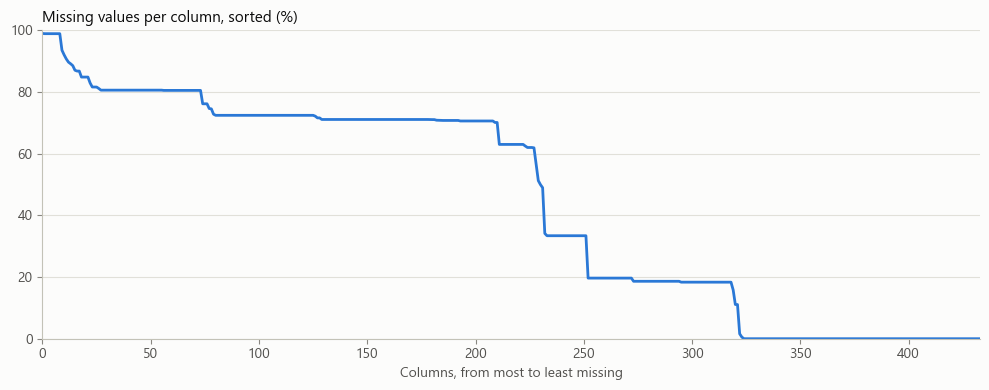

In [7]:
missing = df.drop(columns=["day", "block"]).isna().mean().sort_values(ascending=False)
print(f"{(missing > 0).sum()} of {len(missing)} columns have missing values; "
      f"{(missing == 0).sum()} are complete.")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(np.arange(len(missing)), 100 * missing.to_numpy(), color=BLUE)
ax.set_title("Missing values per column, sorted (%)")
ax.set_xlabel("Columns, from most to least missing")
ax.set_ylim(0, 100)
ax.set_xlim(0, len(missing) - 1)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_missingness.png", dpi=150)
plt.show()

In [8]:
thresholds = [0.5, 0.75, 0.9, 0.95, 0.99]
pd.DataFrame({"missing_above": [f"{t:.0%}" for t in thresholds],
              "columns": [(missing > t).sum() for t in thresholds]})

,missing_above,columns
0,50%,230
1,75%,77
2,90%,12
3,95%,9
4,99%,0


In [9]:
# The 30 most-missing columns: shows where the near-empty group ends.
(100 * missing.head(30)).round(1).to_frame("missing_%")

,missing_%
id_24,99.0
id_25,98.9
id_07,98.9
id_08,98.9
id_21,98.9
id_26,98.9
id_27,98.9
id_22,98.9
id_23,98.9
D7,93.6


In [10]:
family = missing.index.str.rstrip("0123456789").str.rstrip("_")  # V12 -> V, id_05 -> id, card1 -> card
by_family = (100 * missing).groupby(family).agg(columns="size", mean_pct="mean",
                                                min_pct="min", max_pct="max").round(1)
by_family.sort_values(["columns", "mean_pct"], ascending=False)

,columns,mean_pct,min_pct,max_pct
V,339,42.3,0.0,80.6
id,38,81.2,70.1,99.0
D,15,60.6,0.0,93.6
C,14,0.0,0.0,0.0
M,9,62.3,34.2,76.2
card,6,0.4,0.0,1.6
dist,2,77.3,62.5,92.0
addr,2,11.1,11.1,11.1
DeviceInfo,1,74.7,74.7,74.7
R_emaildomain,1,72.2,72.2,72.2


## 5. Transaction amount

Amounts range over several orders of magnitude, so the histogram uses a log10 scale. Each class is
scaled to area 1 (density), so the two shapes can be compared even though fraud is rare.

In [11]:
amount_by_class = df.groupby("isFraud")["TransactionAmt"].describe(percentiles=[0.5, 0.99]).round(2)
amount_by_class.index = ["legitimate", "fraud"]
amount_by_class

,count,mean,std,min,50%,99%,max
legitimate,284339.0,131.64,236.26,0.79,67.95,1051.0,31937.39
fraud,9854.0,135.79,194.15,0.29,76.02,884.0,4191.00


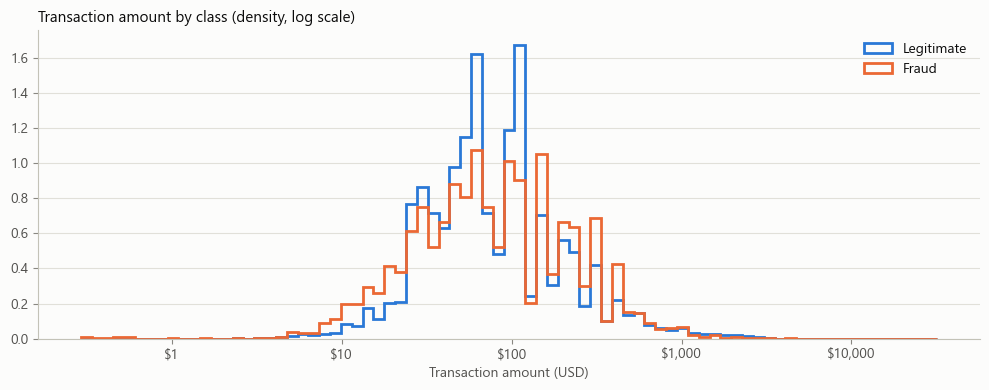

In [12]:
log_amt = np.log10(df["TransactionAmt"])
bins = np.linspace(log_amt.min(), log_amt.max(), 80)

fig, ax = plt.subplots(figsize=(10, 4))
for value, label, color in [(0, "Legitimate", BLUE), (1, "Fraud", ORANGE)]:
    ax.hist(log_amt[df["isFraud"] == value], bins=bins, density=True,
            histtype="step", linewidth=2, color=color, label=label)
ticks = [1, 10, 100, 1_000, 10_000]
ax.set_xticks(np.log10(ticks), [f"${t:,}" for t in ticks])
ax.set_title("Transaction amount by class (density, log scale)")
ax.set_xlabel("Transaction amount (USD)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_amount.png", dpi=150)
plt.show()

## 6. Key categoricals

Fraud rate per category for four low-cardinality columns. Missing values count as their own category.
The table lists every category; the chart leaves out categories with fewer than `MIN_ROWS` rows,
whose rates are too noisy to read. The vertical line is the overall fraud rate.

In [13]:
KEY_CATEGORICALS = ["ProductCD", "card4", "card6", "DeviceType"]
MIN_ROWS = 100  # smaller categories are listed in the table but not plotted


def fraud_rate_by(col: str) -> pd.DataFrame:
    """Rows, frauds and fraud rate (%) per category, with missing values as their own category."""
    values = df[col].astype("object").fillna("missing")
    table = df["isFraud"].groupby(values).agg(rows="size", frauds="sum")
    table["fraud_%"] = (100 * table["frauds"] / table["rows"]).round(2)
    return table.sort_values("rows", ascending=False)


cat_tables = {col: fraud_rate_by(col) for col in KEY_CATEGORICALS}
pd.concat(cat_tables, names=["column", "category"])

rows  frauds  fraud_%
column     category                                 
ProductCD  W                 202143    4052     2.00
           C                  34752    3677    10.58
           R                  26395     822     3.11
           H                  25321     988     3.90
           S                   5582     315     5.64
card4      visa              193366    6269     3.24
           mastercard         91350    3267     3.58
           american express    5837     156     2.67
           discover            3628     159     4.38
           missing               12       3    25.00
card6      debit             209792    4773     2.28
           credit             84363    5079     6.02
           debit or credit       17       0     0.00
           charge card           12       0     0.00
           missing                9       2    22.22
DeviceType missing           208361    4329     2.08
           desktop            53163    2694     5.07
           mobile             32669    2831     8.67

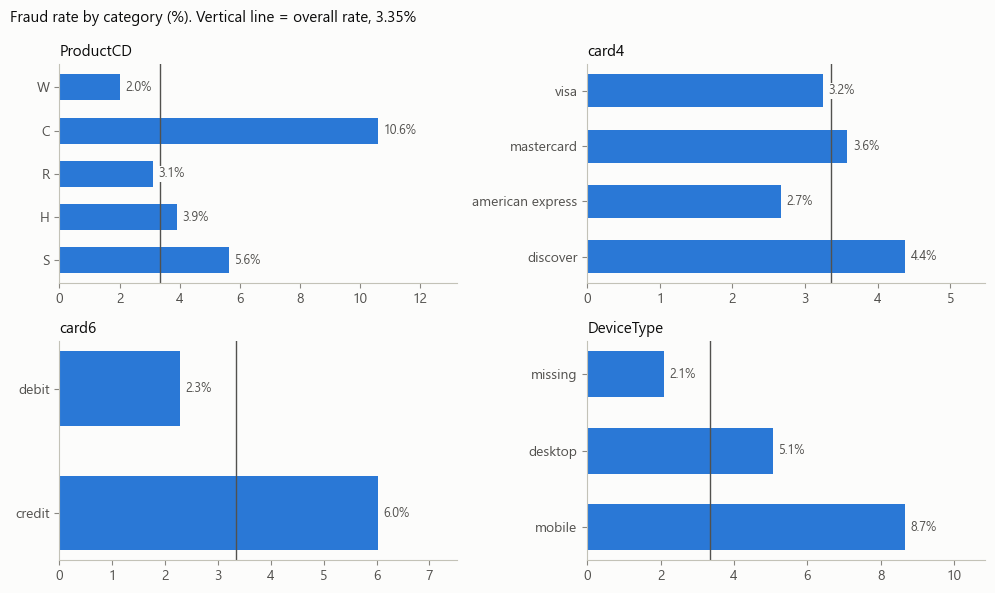

In [14]:
overall = 100 * df["isFraud"].mean()

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, col in zip(axes.flat, KEY_CATEGORICALS):
    table = cat_tables[col][cat_tables[col]["rows"] >= MIN_ROWS]
    ax.barh(table.index, table["fraud_%"], color=BLUE, height=0.6)
    ax.axvline(overall, color=INK_2, linewidth=1)
    for y, rate in enumerate(table["fraud_%"]):
        # Label 4 points right of the bar end; the background keeps it readable over the line.
        ax.annotate(f"{rate:.1f}%", (rate, y), xytext=(4, 0), textcoords="offset points",
                    va="center", color=INK_2, fontsize=9,
                    bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1))
    ax.invert_yaxis()
    ax.set_xlim(0, table["fraud_%"].max() * 1.25)
    ax.grid(False)
    ax.set_title(col)
fig.suptitle(f"Fraud rate by category (%). Vertical line = overall rate, {overall:.2f}%",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_categoricals.png", dpi=150)
plt.show()

## Findings and preprocessing decisions

All numbers come from the outputs above and describe the training rows only (days 0–82).
Blocks 4–6 were not looked at, so these are statements about the training period, not the test period.

### Findings

1. **Class balance.** 9,854 of 294,193 training rows are fraud (3.35%), about 29 legitimate
   transactions per fraud (284,339 / 9,854). The rate is not stable over time: 2.53% in block 1,
   then 4.00% and 4.08% in blocks 2 and 3.
2. **Daily pattern.** Volume ranges from 2,204 to 6,852 transactions a day (mean 3,544). The busiest
   stretch, around days 17–24 with its peak of 6,852 on day 21, also has the lowest fraud rates, down
   to 1.10% on day 24. The daily fraud rate ranges from 1.10% to 6.99%. Both volume and fraud rate move
   over time, so a model trained on one period meets a different mix later.
3. **Frauds per day against the alert budget.** There are 118.72 frauds a day on average (median 117,
   range 51–234). The best possible precision@k on a day is min(1, frauds that day / k). Every day had
   at least 51 frauds, so precision@30 could reach 1 on every day. But k = 150 is above the 75th
   percentile (135), so precision@150 cannot reach 1 on at least three quarters of the days.
4. **Missingness.** 371 of 434 columns have missing values; only 63 are complete. It depends strongly on
   the column family: C columns are complete and card columns nearly so (mean 0.4%), while identity
   (id) columns are missing in 70.1–99.0% of rows (mean 81.2%), consistent with only about 30% of
   transactions having an identity record. The sorted curve has long flat steps: many columns share
   exactly the same missing share (for example a group of V columns at 80.6%), which suggests they are
   recorded together. There is only one clear break at the top: nine identity columns (id_07, id_08,
   id_21 to id_27) are 98.9–99.0% missing, and the next column, D7, is at 93.6%. Below that the curve
   falls smoothly, with no natural cut point.
5. **Missing values carry information.** DeviceType is missing in 208,361 rows (70.8%). Those rows have
   a fraud rate of 2.08%, against 5.07% for desktop and 8.67% for mobile. Whether a value is missing is
   itself a signal.
6. **Transaction amount.** Amounts have a long right tail: for legitimate transactions the mean (131.64)
   is almost twice the median (67.95) and the largest is 31,937.39. Fraud and legitimate amounts overlap
   heavily (medians 76.02 and 67.95), so amount alone separates them poorly. Fraud has relatively more
   small transactions (roughly 5–25 USD in the histogram) and a shorter tail: its 99th percentile is
   884.0 against 1,051.0, and its largest amount is 4,191.00.
7. **Categoricals.** Of the four columns, ProductCD separates fraud rates the most: 10.58% for C against
   2.00% for W, the largest category. Credit cards have a higher fraud rate than debit cards (6.02% vs
   2.28%), and mobile devices higher than desktop (8.67% vs 5.07%). card4 differs little (2.67–4.38%).
   Some categories are tiny (card6 "charge card": 12 rows, "debit or credit": 17 rows), so their rates
   mean nothing on their own.

### Preprocessing decisions

| # | Decision | Evidence | Step |
|---|---|---|---|
| P1 | Every fitted transform (column pruning, encoders, imputer, scaler) is fitted on the training rows only | Volume and fraud rate change over time (findings 1, 2) | 4.4, 6.1 |
| P2 | Imbalance is handled with class weights, not resampling | 3.35% fraud, about 29 legitimate per fraud (finding 1) | 6.1, 7.1 |
| P3 | **Missingness threshold: drop a column when more than 95% of its training values are missing.** On these rows that drops 9 columns: id_07, id_08, id_21 to id_27 | The only clear break in the sorted curve: 98.9–99.0%, then 93.6% (finding 4). A 90% cut would fall in the middle of a smooth slope; 50% or 75% would drop 230 or 77 columns, including DeviceType, whose missingness is informative (finding 5); 99% drops nothing | 4.4: the value goes into config, and the column list is recomputed from the training rows, not hard-coded |
| P4 | Missing values are kept as information: LightGBM receives NaN as-is (it handles missing values itself); logistic regression gets median imputation plus missing flags | Missingness is linked to the fraud rate (finding 5) | 6.1, 7.1 |
| P5 | Add log amount; keep the raw amount for savings and expected loss | Long right tail (finding 6): a linear model is pulled by extreme values, trees are not | 4.1 |
| P6 | "Missing" is kept as its own category; categoricals are frequency-encoded, and low-cardinality ones are one-hot encoded for logistic regression, all fitted on training rows; an unseen category gets 0 | Fraud rates differ clearly between categories, and some categories are tiny (finding 7) | 4.4, 6.1 |

### Implications for evaluation

- Precision@k has a ceiling set by the number of frauds that day (finding 3). A drop in precision from
  k = 100 to k = 150 is partly this ceiling, not the model, so recall@k is reported next to it.
- Because the fraud rate moves between blocks (finding 1), block-4 precision partly reflects block 4's own
  fraud rate. Both models are scored on the same block-4 days, so the comparison between them stays fair.
